# Machine Learning #05 — Autoencoders & Variational Autoencoders 🖼️🔀

In the previous lessons our networks learned to **classify** — they needed labels.
Today the network learns **without any labels**: it learns to **compress data and
reconstruct it back**. This is our first *unsupervised* deep-learning model.

Everything runs in **PyTorch**, and we build it up in three steps:

> **image → encoder → latent vector → decoder → reconstructed image**

**Roadmap** 🗺️
- 🧠 **Autoencoder (AE)** — compress & reconstruct MNIST digits.
- 🚨 **Outlier detection** — reuse the trained AE: *what it cannot reconstruct is suspicious*.
- 🔀 **Variational Autoencoder (VAE)** — a **probabilistic** latent space we can
  **sample from to generate brand-new digits**.

At the end there are **4 hands-on activities** ✏️.

## What is an autoencoder? 🔎

An **autoencoder** is a neural network trained to **copy its input to its output** —
but through a narrow **bottleneck** that forces it to keep only the essentials.

It has **two parts**:

- **Encoder** 🗜️ — compresses the input image into a small **latent vector**
  (the *bottleneck* / *code*). The network decides on its own what to store —
  ideally the important features (stroke thickness, slant, shape).
- **Decoder** 🔁 — reconstructs the original image back from that latent vector.

The trick is in the training data: **the target is the input itself.** We minimise
the difference between the input image and its reconstruction. No class labels needed.

### Why binary cross-entropy (BCE)?

MNIST pixels are scaled to $[0, 1]$. We use their intensities as **soft targets**
and compare them with the decoder's sigmoid outputs using **BCE**:

$$\text{BCE} = -\frac{1}{N}\sum_{i=1}^{N}\big[\,y_i \log(p_i) + (1-y_i)\log(1-p_i)\,\big]$$

where $y_i$ is the target intensity and $p_i$ the reconstructed intensity. Here $N$
counts all pixels in the batch, matching the default mean reduction of `nn.BCELoss`.
For binary pixels, BCE is the negative log-likelihood of independent Bernoulli outputs;
using it with grayscale intensities is a common soft-target reconstruction loss.

See the [PyTorch BCE documentation](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCELoss.html).

> 💡 **BCE penalises confidently wrong predictions.** For a fixed target intensity $y$,
> the loss is minimised at $p = y$. A grey target of 0.5 therefore favours a prediction
> of 0.5. Swapping black and white in both the target and prediction leaves BCE unchanged.

### Autoencoder vs. classifier — different goals 🎯

Both a classifier and an autoencoder produce a latent vector, but they optimise for
**different things**:

| | Autoencoder | Classifier |
|---|---|---|
| Latent goal | keep enough info to **reconstruct** the image | make classes **easy to separate** |
| Loss | reconstruction (BCE) | cross-entropy over classes |
| Labels | **none** (unsupervised) | required (supervised) |
| Latent shape | preserves visual detail | pushes classes apart |

**TL;DR:** use classifiers for classification and autoencoders for autoencoder tasks —
the loss function is what shapes the latent space.

## Imports and setup ⚙️

Remember to set a **GPU** runtime in Colab! (*Runtime → Change runtime type → GPU*)

The setup cell installs `torchinfo` for model summaries and `tqdm` for progress bars.
Both are also declared in the project's dependencies for local installation.

In [ ]:
%pip install torchinfo tqdm

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms

import torchinfo
from tqdm.auto import tqdm

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use the GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:", torch.__version__)
print("device:", device)

torch version: 2.6.0+cu124
device: cuda


c:\Users\recka\Desktop\alex\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The data — MNIST 🔢

MNIST is the classic dataset of handwritten digits (0–9), 28×28 grayscale.

We **resize the images to 32×32** to use an 8×8 feature map after two pooling steps:

$$32 \rightarrow 16 \rightarrow 8 \quad\text{and}\quad 8 \rightarrow 16 \rightarrow 32$$

This is a convenient design choice. With two pooling steps, 28×28 would also work:
`28 → 14 → 7`, followed by `7 → 14 → 28`, provided the linear and unflatten layers
were adjusted to a 7×7 feature map. Odd-size rounding would matter if we added a third
pooling step (`7 // 2 = 3`).

We use **one** torchvision pipeline for the *whole* notebook (both the AE and the VAE).

### Train / validation / test 🔀

1. **Train** (50 000) — the model learns from these.
2. **Validation** (10 000) — split off the training set; use its reconstruction loss to
   compare model settings and its clean reconstruction errors to calibrate an outlier
   threshold. These examples do not contribute training gradients.
3. **Test** (10 000) — held out for final reconstruction examples, outlier evaluation,
   and latent-space plots after model settings and thresholds have been chosen.

Generating images from random latent vectors uses **no test images**.

In [2]:
transform = transforms.Compose([
    transforms.Resize(32),   # 28x28 -> 32x32  
    transforms.ToTensor(),   # PIL image -> tensor of shape (1, 32, 32), values in [0, 1]
])

from torch.utils.data import random_split

full_train = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)


val_size   = 10_000
train_size = len(full_train) - val_size
train_subset, val_subset = random_split(
    full_train, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED),
)

train_loader = DataLoader(train_subset, batch_size=128, shuffle=True)
val_loader   = DataLoader(val_subset,   batch_size=128, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train images:     ", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:      ", len(test_dataset))

Train images:      50000
Validation images: 10000
Test images:       10000


In [3]:
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape)
print("Pixel range:", images.min().item(), "->", images.max().item())

Batch shape: torch.Size([128, 1, 32, 32])
Pixel range: 0.0 -> 1.0


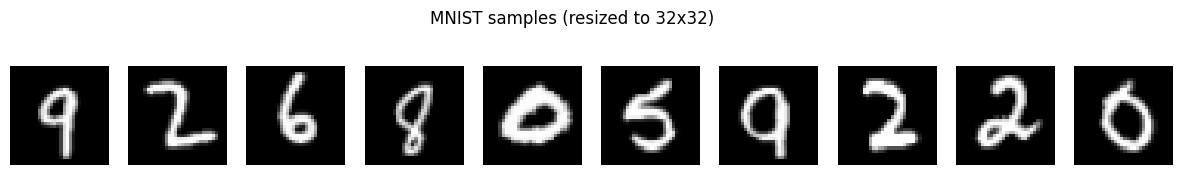

In [4]:
def show_images(images, n=10, title=None):
    images = images.detach().cpu().numpy()
    plt.figure(figsize=(15, 2.2))
    for i in range(n):
        ax = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        ax.axis("off")
    if title:
        plt.suptitle(title)
    plt.show()

show_images(images, title="MNIST samples (resized to 32x32)")

## Build the autoencoder 🧠

We build the AE as an **`nn.Module`** class. It has an `encoder`, a `decoder`, and a **latent vector** in between.

**Encoder** — two `Conv2d` + `MaxPool2d` blocks shrink the image `32 → 16 → 8`,
then a `Linear` layer squeezes everything into a `latent_dim`-sized vector.

**Decoder** — the mirror image: a `Linear` layer expands the vector back, then
**`ConvTranspose2d`** layers (a *learnable* upsampling) grow it `8 → 16 → 32`.

- The final activation is **`Sigmoid`**, squeezing outputs into $(0, 1)$ to match the
  normalised pixels.
- `padding=1` keeps the spatial size after each conv; `output_padding=1` makes the
  transposed conv land exactly on the doubled size.

In [5]:
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()
        self.latent_dim = latent_dim

        # Encoder: 32x32 -> 16x16 -> 8x8 -> flatten -> latent vector
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                              # 32 -> 16
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                              # 16 -> 8
            nn.Flatten(),                                 # 32 * 8 * 8 = 2048
            nn.Linear(32 * 8 * 8, latent_dim),            # the bottleneck!
        )

        # Decoder: latent vector -> 8x8 -> 16x16 -> 32x32
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32 * 8 * 8), nn.ReLU(),
            nn.Unflatten(1, (32, 8, 8)),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 8 -> 16
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(), # 16 -> 32
        )

    def forward(self, x):
        z = self.encoder(x)      # compress
        out = self.decoder(z)    # reconstruct
        return out


model = ConvAutoencoder(latent_dim=32).to(device)
print(model)

ConvAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=2048, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=2048, bias=True)
    (1): ReLU()
    (2): Unflatten(dim=1, unflattened_size=(32, 8, 8))
    (3): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (4): ReLU()
    (5): ConvTranspose2d(16, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (6): Sigmoid()
  )
)


In [6]:
torchinfo.summary(model, input_size=(1, 1, 32, 32))

Layer (type:depth-idx)                   Output Shape              Param #
ConvAutoencoder                          [1, 1, 32, 32]            --
├─Sequential: 1-1                        [1, 32]                   --
│    └─Conv2d: 2-1                       [1, 16, 32, 32]           160
│    └─ReLU: 2-2                         [1, 16, 32, 32]           --
│    └─MaxPool2d: 2-3                    [1, 16, 16, 16]           --
│    └─Conv2d: 2-4                       [1, 32, 16, 16]           4,640
│    └─ReLU: 2-5                         [1, 32, 16, 16]           --
│    └─MaxPool2d: 2-6                    [1, 32, 8, 8]             --
│    └─Flatten: 2-7                      [1, 2048]                 --
│    └─Linear: 2-8                       [1, 32]                   65,568
├─Sequential: 1-2                        [1, 1, 32, 32]            --
│    └─Linear: 2-9                       [1, 2048]                 67,584
│    └─ReLU: 2-10                        [1, 2048]                 --
│  

## Train the autoencoder ⭐


> 🔑 **The target is the input.** We compute the loss between the reconstruction and the
> **original image** — `criterion(recon, images)` — not against any label.

For each batch we always do the same five steps:
`zero_grad → forward → loss → backward → step`.

In [ ]:
criterion = nn.BCELoss()                                   # pixels in [0,1] -> BCE
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
ae_epochs  = 5

train_losses, val_losses = [], []
for epoch in range(ae_epochs):
    # ---- training ----
    model.train()
    running = 0.0
    for images, _ in train_loader:            # labels are ignored -> unsupervised
        images = images.to(device)

        optimizer.zero_grad()                 # 1) clear old gradients
        recon = model(images)                 # 2) forward pass
        loss  = criterion(recon, images)      # 3) loss vs the INPUT itself (key!)
        loss.backward()                       # 4) backprop
        optimizer.step()                      # 5) update the weights

        running += loss.item() * images.size(0)
    train_loss = running / len(train_subset)

    # ---- validation (no gradients, model in eval mode) ----
    model.eval()
    v_running = 0.0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            v_running += criterion(model(images), images).item() * images.size(0)
    val_loss = v_running / len(val_subset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print(f"Epoch {epoch + 1}/{ae_epochs}   train = {train_loss:.4f}   val = {val_loss:.4f}")

In [ ]:
plt.figure()
plt.plot(range(1, ae_epochs + 1), train_losses, marker="o", label="train")
plt.plot(range(1, ae_epochs + 1), val_losses,   marker="s", label="validation")
plt.xlabel("epoch")
plt.ylabel("BCE loss")
plt.title("Autoencoder training")
plt.legend()
plt.grid(True)
plt.show()

> 💡 Look for a **downward trend**, allowing for fluctuations between epochs. If the
> validation loss stops improving or rises while training loss keeps falling, that can
> indicate overfitting. A single increase is not enough to establish the trend.

## How good are the reconstructions? 🖼️

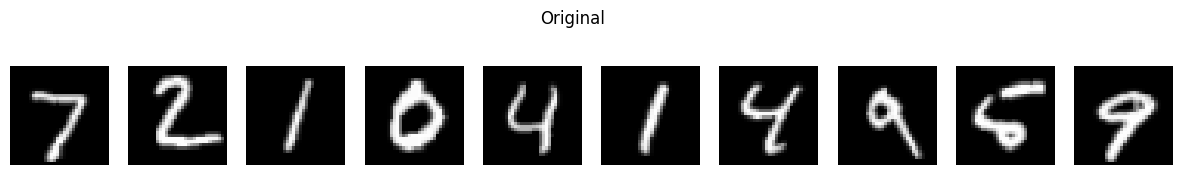

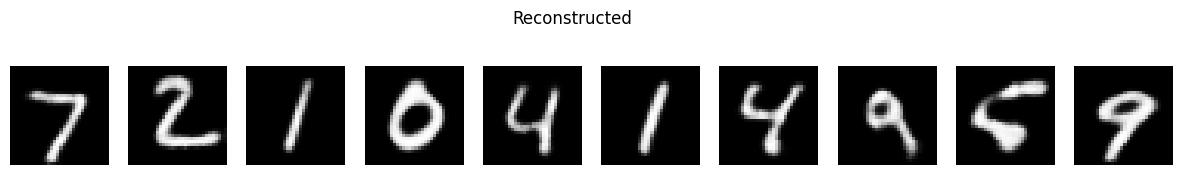

In [9]:
model.eval()
test_images, _ = next(iter(test_loader))
test_images = test_images.to(device)

with torch.no_grad():
    reconstructed = model(test_images)

show_images(test_images,   title="Original")
show_images(reconstructed, title="Reconstructed")

## Looking inside: the latent vectors ⚡

Let's make the bottleneck concrete. We take **one** digit and follow it through the
whole autoencoder:

- **Left** — the original image: **1024 pixels** (32×32).
- **Middle** — its **latent code**: the 32 numbers the encoder squeezed it into.
  Notice the values are **not** limited to [0, 1] — the bottleneck is a plain `Linear`
  layer, so they can be any real number (positive or negative).
- **Right** — the **reconstruction** the decoder rebuilds *from those 32 numbers alone*.

In [ ]:
# Pick one test digit and show the compression end-to-end:
# original image  ->  its 32 latent numbers  ->  reconstruction
model.eval()
img, _ = test_dataset[100]                # one image, shape (1, 32, 32)
img = img.unsqueeze(0).to(device)        # add batch dim -> (1, 1, 32, 32)

with torch.no_grad():
    z = model.encoder(img)               # the 32 latent numbers
    recon = model.decoder(z)             # reconstruct from them

z = z.squeeze(0).cpu().numpy()            # (32,)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

# 1) original
axes[0].imshow(img.squeeze().cpu().numpy(), cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

# 2) the latent vector as a bar chart
axes[1].bar(range(len(z)), z)
axes[1].set_title(f"Latent code ({len(z)} numbers)")
axes[1].set_xlabel("latent dimension")
axes[1].set_ylabel("value")

# 3) reconstruction
axes[2].imshow(recon.squeeze().cpu().numpy(), cmap="gray")
axes[2].set_title("Reconstruction")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:

model.eval()
img, _ = test_dataset[1014]              
img = img.unsqueeze(0).to(device)

with torch.no_grad():
    z = model.encoder(img)
    recon = model.decoder(z)

z = z.squeeze(0).cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

axes[0].imshow(img.squeeze().cpu().numpy(), cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].bar(range(len(z)), z)
axes[1].set_title(f"Latent code ({len(z)} numbers)")
axes[1].set_xlabel("latent dimension")
axes[1].set_ylabel("value")

axes[2].imshow(recon.squeeze().cpu().numpy(), cmap="gray")
axes[2].set_title("Reconstruction")
axes[2].axis("off")

plt.tight_layout()
plt.show()

## Outlier detection with the autoencoder 🚨

An AE trained on clean digits may reconstruct unfamiliar or corrupted inputs less well.
We can use its **reconstruction error** as an outlier score.

**Recipe:**
1. Measure reconstruction errors on **clean validation digits** for threshold calibration.
2. Take clean test digits and make corrupted copies by adding strong noise.
3. Compute the same score $\lVert x - \hat{x}\rVert^2$ for both test groups.
4. Compare their distributions; in Activity 4, evaluate a threshold chosen from validation.

We trained with BCE, but use **summed squared error** as the anomaly score here. These
are different measures; calibrate the threshold using the same score used at evaluation.

This is a demonstration with synthetic corruption. Reconstruction error is a heuristic:
some anomalies can reconstruct well, and unusual clean examples can have high error.
Performance on noisy digits alone does not establish performance on real-world anomalies.

In [ ]:
def reconstruction_errors(model, images):
    """Return summed squared reconstruction error for each image in a batch."""
    model.eval()
    with torch.no_grad():
        images = images.to(device)
        recon = model(images)
        return (images - recon).square().flatten(1).sum(1).cpu().numpy()


# Calibration data for Activity 4: use the clean VALIDATION split.
err_val_clean = np.concatenate([
    reconstruction_errors(model, batch_images)
    for batch_images, _ in val_loader
])

# Evaluation data: clean TEST samples and synthetic noisy copies.
clean, _ = next(iter(DataLoader(test_dataset, batch_size=200, shuffle=False)))
noise_factor = 0.4
noisy = torch.clamp(clean + noise_factor * torch.randn_like(clean), 0.0, 1.0)

err_clean = reconstruction_errors(model, clean)
err_noisy = reconstruction_errors(model, noisy)

show_images(noisy, title=f"Corrupted 'outliers' (noise_factor={noise_factor})")

In [ ]:
# Compare the test distributions; calibrate thresholds using err_val_clean.
plt.figure(figsize=(9, 5))
plt.hist(err_clean, bins=40, alpha=0.7, label="clean digits")
plt.hist(err_noisy, bins=40, alpha=0.7, label="noisy outliers")
plt.xlabel("summed squared reconstruction error per image")
plt.ylabel("count")
plt.title("Clean vs. outlier reconstruction error")
plt.legend()
plt.show()

# Variational Autoencoder (VAE) 📒

A plain autoencoder maps each image to **one point** in latent space. Its reconstruction
objective does not require these codes to follow a known distribution, so sampling an
arbitrary random vector may produce a poor image.

A **VAE** encodes each image into a **diagonal Gaussian distribution**:

- the encoder outputs a **mean** `z_mean` ($\mu$) and a **log-variance** `z_log_var`
  ($\log \sigma^2$) for each latent dimension,
- we **sample** a latent vector from that distribution,
- the decoder reconstructs from the sample.

The loss also includes a **KL-divergence term** that encourages these distributions
towards a standard normal prior $\mathcal{N}(0, I)$. Together with reconstruction
training, this encourages useful decoding near the prior's typical values. Sampling
alone does not impose the prior, and good generated images are not guaranteed.

The method is introduced in [Auto-Encoding Variational Bayes](https://arxiv.org/abs/1312.6114).

## The reparameterisation trick 🎲 — the heart of the VAE

An ordinary draw from `torch.distributions.Normal(...).sample()` does not provide a
path for autograd to differentiate the sample with respect to the distribution's
parameters. The **reparameterisation trick** expresses the sample as:

$$z = \mu + \sigma \odot \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, I)$$

- $\mu$ (`z_mean`) — the centre of the encoded distribution,
- $\sigma$ (`exp(0.5 * z_log_var)`) — the standard deviation in each dimension,
- $\varepsilon$ — noise independent of the encoder parameters.

For a fixed noise draw, $z$ is differentiable with respect to $\mu$ and $\sigma$.
This lets reconstruction gradients reach the encoder. Our `Sampling` module implements
this formula explicitly; `Normal(...).rsample()` is PyTorch's reparameterised alternative.

> 💡 We keep `z_log_var` (log-variance) instead of the variance directly. It can take
> any real value (negative or positive), which is numerically friendlier, and
> `exp(0.5 · z_log_var)` always gives a positive standard deviation.

## The VAE loss = reconstruction + KL 💡

We implement two terms. For **one image**, the objective is:

$$\mathcal{L}(x) = \underbrace{\sum_{i=1}^{1024}\text{BCE}(\hat{x}_i, x_i)}_{\text{reconstruct well}}
\;+\; \underbrace{\left(-\tfrac{1}{2}\sum_j\big(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\big)\right)}_{\text{KL divergence}}$$

- **Reconstruction** — BCE summed over the image's pixels, using one sampled latent
  vector to estimate the expected reconstruction term.
- **KL divergence** — the analytic divergence from the encoded diagonal Gaussian to
  $\mathcal{N}(0, I)$. It is zero when every $\mu_j = 0$ and $\sigma_j = 1$.

`vae_loss` sums these terms across the batch. The epoch loop divides the total by the
number of images to report an **average loss per image**. This follows the reduction
used in the [official PyTorch VAE example](https://github.com/pytorch/examples/blob/main/vae/main.py).

## Build the VAE 🔀

Three new ingredients compared to the plain AE:

1. **`Sampling`** — a tiny module implementing the reparameterisation trick.
2. **Two output heads** `z_mean` and `z_log_var` instead of one latent vector.
3. **`forward` returns three things** — `reconstruction, z_mean, z_log_var` — because the
   loss needs all of them.

In [ ]:
class Sampling(nn.Module):
    # Reparameterisation trick:  z = mean + std * epsilon,  epsilon ~ N(0, 1)
    def forward(self, z_mean, z_log_var):
        # Sampling remains stochastic in eval mode.
        epsilon = torch.randn_like(z_mean)               # external noise ~ N(0,1)
        return z_mean + torch.exp(0.5 * z_log_var) * epsilon

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.latent_dim = latent_dim

        # Encoder: 32x32 -> 16x16 -> 8x8 -> flatten
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                       # 32 -> 16
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                       # 16 -> 8
            nn.Flatten(),                          # 64 * 8 * 8 = 4096
        )
        # Two heads describing the latent DISTRIBUTION (not a single point)
        self.z_mean    = nn.Linear(64 * 8 * 8, latent_dim)   # mean  (mu)
        self.z_log_var = nn.Linear(64 * 8 * 8, latent_dim)   # log-variance (log sigma^2)
        self.sampling  = Sampling()

        # Decoder: latent -> 8x8 -> 16x16 -> 32x32
        self.decoder_input = nn.Linear(latent_dim, 64 * 8 * 8)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (64, 8, 8)),
            nn.ConvTranspose2d(64, 64, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 8 -> 16
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),  # 16 -> 32
            nn.Conv2d(32, 1, 3, padding=1), nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.z_mean(h), self.z_log_var(h)

    def decode(self, z):
        h = self.decoder_input(z)
        return self.decoder(h)

    def forward(self, x):
        z_mean, z_log_var = self.encode(x)
        z = self.sampling(z_mean, z_log_var)
        return self.decode(z), z_mean, z_log_var


# latent_dim = 2 so we can later plot the latent space in 2D
vae = VAE(latent_dim=2).to(device)
torchinfo.summary(vae, input_size=(1, 1, 32, 32))

In [ ]:
def vae_loss(recon_x, x, z_mean, z_log_var):
    # Sum over all images AND pixels; epoch reporting divides by the image count.
    recon = F.binary_cross_entropy(recon_x, x, reduction="sum")
    # Sum KL over all images and latent dimensions, relative to N(0, I).
    kl = -0.5 * torch.sum(1 + z_log_var - z_mean.pow(2) - z_log_var.exp())
    return recon + kl

## Train the VAE ⭐

Same five-step loop as before — only the forward pass now returns three values, and we
call our custom `vae_loss`. We wrap the loader in `tqdm` for a progress bar.

In [ ]:
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
vae_epochs  = 10

vae_train_losses, vae_val_losses = [], []
for epoch in range(vae_epochs):
    # ---- training ----
    vae.train()
    running = 0.0
    for images, _ in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{vae_epochs}", leave=False):
        images = images.to(device)

        optimizer.zero_grad()
        recon, z_mean, z_log_var = vae(images)                 # forward: 3 outputs
        loss = vae_loss(recon, images, z_mean, z_log_var)      # BCE + KL
        loss.backward()
        optimizer.step()

        running += loss.item()
    train_loss = running / len(train_subset)

    # ---- validation ----
    vae.eval()
    v_running = 0.0
    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)
            recon, z_mean, z_log_var = vae(images)
            v_running += vae_loss(recon, images, z_mean, z_log_var).item()
    val_loss = v_running / len(val_subset)

    vae_train_losses.append(train_loss)
    vae_val_losses.append(val_loss)
    print(f"Epoch {epoch + 1}/{vae_epochs}   train = {train_loss:.2f}   val = {val_loss:.2f}")

The printed VAE loss is **per image**: summed pixel BCE plus summed latent KL,
averaged over the images in the split. The AE reports BCE **per pixel**, so their loss
values are not directly comparable. The relative scale of reconstruction and KL matters;
Activity 3 explores it with a KL weight.

Watch the trend across epochs. Validation also draws latent samples in our implementation,
so it has sampling noise: `vae.eval()` does not disable the custom `Sampling` module.

In [ ]:
plt.figure()
plt.plot(range(1, vae_epochs + 1), vae_train_losses, marker="o", label="train")
plt.plot(range(1, vae_epochs + 1), vae_val_losses,   marker="s", label="validation")
plt.xlabel("epoch")
plt.ylabel("VAE loss per image (summed pixel BCE + KL)")
plt.title("VAE training")
plt.legend()
plt.grid(True)
plt.show()

## Reconstructions from the VAE 🖼️

First a sanity check — the VAE should still reconstruct real inputs.

In [ ]:
vae.eval()
test_images, test_labels = next(iter(test_loader))
test_images = test_images.to(device)

with torch.no_grad():
    recon, _, _ = vae(test_images)

show_images(test_images, title="Original")
show_images(recon,       title="VAE reconstruction")

> 🔎 Reconstructions may look **blurry**. A two-dimensional bottleneck limits the
> information available to the decoder. KL regularisation and a pixel-wise reconstruction
> objective can also contribute to smooth outputs. Increasing the latent size may help,
> but a larger latent space alone does not guarantee sharp reconstructions.

## Generating NEW digits 🤔✨

To generate images, we use the **decoder alone**. Sample latent vectors from the standard
normal prior $\mathcal{N}(0, I)$ and decode them. KL regularisation encourages the
encoded distributions towards this prior during training.

These outputs are generated without providing an input digit. Their quality and diversity
depend on the learned model; generation does not guarantee that every image is recognisable
or different from every training example.

In [ ]:
vae.eval()
with torch.no_grad():
    z = torch.randn(10, vae.latent_dim).to(device)   # random points from N(0, 1)
    generated = vae.decode(z)

show_images(generated, title="Generated digits (sampled from N(0,1))")

## The latent manifold 📈

With a 2D latent space, we can decode a grid of $(z_1, z_2)$ values to inspect a **bounded
region**. The plot below covers $[-2, 2]^2$; it is a uniform grid, not a random sample
from the normal prior. Look for gradual changes in the generated shapes across the grid.

In [ ]:
def plot_latent(model, n=20, scale=2.0, device=device):
    if model.latent_dim != 2:
        raise ValueError("This grid visualisation requires latent_dim=2.")
    digit = 32
    grid_x = torch.linspace(-scale, scale, n)
    grid_y = torch.linspace(-scale, scale, n).flip(0)   # flip so +y points up

    canvas = np.zeros((digit * n, digit * n))
    model.eval()
    with torch.no_grad():
        for i, yi in enumerate(grid_y):
            for j, xi in enumerate(grid_x):
                z = torch.tensor([[xi.item(), yi.item()]], device=device)
                img = model.decode(z)[0, 0].cpu().numpy()
                canvas[i * digit:(i + 1) * digit, j * digit:(j + 1) * digit] = img

    plt.figure(figsize=(10, 10))
    plt.imshow(canvas, cmap="Greys_r")
    plt.title("Latent manifold: decode a grid of (z1, z2)")
    plt.axis("off")
    plt.show()

plot_latent(vae)

## Where does each digit live? 🗺️

Encode test digits and scatter their `z_mean` in 2D, coloured by their true labels.
Labels are used **only to colour this plot**, not to train the VAE. Visually similar
digits may cluster, but overlap is expected because the objective does not explicitly
separate digit classes.

In [ ]:
zs, ys = [], []
vae.eval()
with torch.no_grad():
    for images, lbls in test_loader:
        m, _ = vae.encode(images.to(device))
        zs.append(m.cpu())
        ys.append(lbls)

zs = torch.cat(zs).numpy()
ys = torch.cat(ys).numpy()

plt.figure(figsize=(8, 7))
sc = plt.scatter(zs[:, 0], zs[:, 1], c=ys, cmap="tab10", s=4)
plt.colorbar(sc, ticks=range(10), label="digit")
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Latent space coloured by digit")
plt.show()

# Activities ✏️

Use **validation loss and validation examples** to compare your model choices. Start
from a fresh model and optimizer for each trial, keeping the seed, data, and training
budget fixed where possible. Reserve test results for reporting after those choices.

Keep the original trained AE and its error arrays for Activity 4; use separate model
variables for the bottleneck and denoising experiments.

## Activity 1 — Squeeze the bottleneck 🗜️

The `latent_dim` of the autoencoder controls how much information survives the bottleneck.

- Rebuild and retrain `ConvAutoencoder` with **three** different latent sizes,
  e.g. `8`, `32`, `128`.
- Compare validation reconstruction loss and show the same validation images for each model.

## Activity 2 — Denoising autoencoder 🧽

A **denoising** autoencoder learns to *remove* noise: it receives a **noisy** image as
input but is trained to output the **clean** one.

- The cell below is **pre-filled** to build separate noisy/clean training and validation pairs.
- Then train an autoencoder where the **input is `noisy`** and the **target is `clean`**
  (i.e. `criterion(model(noisy_batch), clean_batch)`).
- Measure validation loss against the **clean validation targets**.
- Experiment with **`noise_factor` = 0.1, 0.5, 0.9**, rebuilding both sets of noisy pairs,
  and write a short note on how well the model recovers the validation digits. 📒

In [ ]:
# --- pre-filled helper: build clean + noisy training and validation pairs ---
def make_noisy(dataset, noise_factor=0.5, n=10000):
    loader = DataLoader(dataset, batch_size=n, shuffle=True)
    clean, _ = next(iter(loader))
    noisy = torch.clamp(clean + noise_factor * torch.randn_like(clean), 0.0, 1.0)
    return clean, noisy

noise_factor = 0.5
clean_x, noisy_x = make_noisy(train_subset, noise_factor=noise_factor)
val_clean_x, val_noisy_x = make_noisy(val_subset, noise_factor=noise_factor)

# quick look: top row = clean target, bottom row = noisy input
show_images(clean_x, title="Clean (target)")
show_images(noisy_x, title=f"Noisy input (noise_factor={noise_factor})")

# Tip: wrap them in a DataLoader for training
noisy_loader = DataLoader(TensorDataset(noisy_x, clean_x), batch_size=128, shuffle=True)
noisy_val_loader = DataLoader(TensorDataset(val_noisy_x, val_clean_x), batch_size=128, shuffle=False)

## Activity 3 — β-VAE: tune the KL weight ⚖️

The VAE loss balances reconstruction against the KL term. A **β-VAE** simply weights the
KL term by a factor **β**:

$$\mathcal{L} = \text{BCE} + \beta \cdot \mathcal{L}_{KL}$$

- Write a `vae_loss_beta(..., beta)` and retrain with e.g. `beta = 0.5`, `1.0`, `4.0`.
- Keep the same reconstruction/KL reductions as `vae_loss`; changing only one reduction changes their relative weight.
- Compare reconstruction BCE and KL **separately** on validation data, plus validation
  reconstructions and latent plots. Total losses with different β values are different
  objectives, so their numeric values are not directly comparable.

## Activity 4 — Outlier threshold 🚨

Use the error arrays from the original AE's outlier-detection section:

- Choose a target false-positive rate, for example 1%, and compute a threshold from
  **`err_val_clean`** (the 99th percentile for this example).
- Keep that threshold fixed. Flag test errors above it in **`err_clean`** and **`err_noisy`**.
- Report how many clean and noisy test images are flagged, including false-positive and
  detection rates (a mini confusion matrix).

Choose the percentile using validation data. If you change the AE or the error metric,
recompute the validation errors and calibrate a new threshold before test evaluation.